# Train and evaluate a model on the six folds

**How to use:** copy this notebook (e.g. `train_random_forest.ipynb`), set `MODEL_NAME` and `make_model()` in the settings cell, and run everything.
Results are saved to `results/`, so the team can compare every model in one table (last section).

- **The question:** for every I-5 northbound station in District 12, every 5 minutes, *will the station be congested (measured speed < 40 mph)
  at any point in the next 30 minutes?*
- **Features:** everyone uses `sf.SHARED_FEATURES` from `safeflow_features.py` (keep that file next to this notebook).
- **Validation:** six quarterly walk-forward folds, 2024 Q1 to 2025 Q2. Each trains on everything from January 2023 up to 7 days before the quarter.
  The July–December 2025 holdout is never read.
- **Main metric:** *AP, onsets*: average precision on stations not congested now (random guessing ≈ 0.05).

In [3]:
# Resolve repository paths from the root or any notebook subfolder.
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "notebooks" / "safeflow_features.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Launch this notebook from inside the SafeFlow repository")
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "notebooks"))

from datetime import date
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import safeflow_features as sf

pd.set_option("display.width", 160)

In [4]:
# ---- Settings: change these ------------------------------------------------------------------------------------------
MODEL_NAME = "boosted_trees"
QUICK_RUN = False
TRAIN_SAMPLE = 2_000_000
DATA_DIR = None

def make_model():
    from sklearn.ensemble import HistGradientBoostingClassifier
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=50, early_stopping=False, random_state=0)
# -------------------------------------------------------------------------------------------------------------------

## 1. Load the data

In [5]:
df = sf.build_dataset(DATA_DIR)
FEATURES = sf.SHARED_FEATURES
print(f"{len(FEATURES)} shared features: {', '.join(FEATURES)}")

read 100/1094 files (1s)
read 200/1094 files (1s)
read 300/1094 files (2s)
read 500/1094 files (3s)
read 600/1094 files (4s)
read 800/1094 files (6s)
read 900/1094 files (6s)
624 weekdays used out of 1094 files (182 holdout files skipped, never read)


/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:362: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  long = wide.stack(future_stack=True).swaplevel()
/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:315: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["y_speed_real"] = ahead["real"].fillna(False).astype(bool).to_numpy()


4,819,328 rows | 46 stations | scored rows 54% | onsets 13,573
29 shared features: speed_anomaly, occ_anomaly, typical_congestion_30, speed_delta_2, flow, down_minus_here, up_minus_here, tod_sin, tod_cos, dow, pm, onramp_flow_up, offramp_flow_down, jam_distance_down, min_speed_down_anomaly, jam_distance_change_10, speed, occupancy, speed_delta_1, speed_delta_3, upstream_speed_delta_1, upstream_speed_delta_2, upstream_speed_delta_3, downstream_speed_delta_1, downstream_speed_delta_2, upstream_distance_miles, slow_last_30, minutes_since_slow, speed_lag_30


## 2. Train and score on each fold
For each fold: rebuild the fold-dependent features from that fold's training days, train on rows whose outcome was measured (`y_known`),
predict every validation row, and score.

In [6]:
fold_results, predictions = [], []
for fold in sf.folds(df, only_last=QUICK_RUN):
    sf.add_typical_features(df, fold.train)
    train = df[fold.train & df["y_known"]]
    if TRAIN_SAMPLE and len(train) > TRAIN_SAMPLE:
        train = train.sample(TRAIN_SAMPLE, random_state=0)
    val = df[fold.val]

    model = make_model().fit(train[FEATURES], train["y"])
    probability = model.predict_proba(val[FEATURES])[:, 1]

    fold_results.append({"fold": fold.name, **sf.score(val, probability)})
    kept = val[sf.KEY + ["date", "y", "y_known", "congested_now", "real", "onset"]].copy()
    predictions.append(kept.assign(probability=probability))
    print(f"{fold.name}: AP onsets {fold_results[-1]['AP, onsets']:.3f} | caught ≥15 min {fold_results[-1]['caught ≥15 min']:.0%} | "
          f"false alarms/day {fold_results[-1]['false alarms / day']:.1f}")

fold_results = pd.DataFrame(fold_results).set_index("fold")
predictions = pd.concat(predictions, ignore_index=True).sort_values(sf.KEY).reset_index(drop=True)

/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


2024-01 to 2024-03: AP onsets 0.762 | caught ≥15 min 70% | false alarms/day 38.3


/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


2024-04 to 2024-06: AP onsets 0.784 | caught ≥15 min 65% | false alarms/day 30.0


/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


2024-07 to 2024-09: AP onsets 0.757 | caught ≥15 min 62% | false alarms/day 28.4


... (2 outputs left out)

/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


2025-01 to 2025-03: AP onsets 0.755 | caught ≥15 min 62% | false alarms/day 29.7


/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()


2025-04 to 2025-06: AP onsets 0.768 | caught ≥15 min 62% | false alarms/day 29.9


## 3. Results per fold
Alert metrics use a threshold of 0.5 (alert when the probability is at least 50%). The spread across folds shows how stable the model is.

In [7]:
table = fold_results.copy()
table.loc["mean"] = fold_results.mean()
table.loc["std"] = fold_results.std()
table.round(3)

,"AP, onsets","AP, all",Brier,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min),onsets
fold,,,,,,,,,
2024-01 to 2024-03,0.762,0.964,0.022,0.698,38.323,6.828,0.895,25.000,1706.000
2024-04 to 2024-06,0.784,0.964,0.020,0.648,29.968,4.589,0.912,25.000,1453.000
2024-07 to 2024-09,0.757,0.962,0.023,0.620,28.391,4.516,0.912,25.000,1491.000
2024-10 to 2024-12,0.772,0.970,0.023,0.645,30.435,4.835,0.920,25.000,1546.000
2025-01 to 2025-03,0.755,0.968,0.022,0.618,29.738,4.888,0.919,25.000,1561.000
2025-04 to 2025-06,0.768,0.968,0.021,0.616,29.889,4.573,0.922,20.000,1536.000
mean,0.766,0.966,0.022,0.641,31.124,5.038,0.913,24.167,1548.833
std,0.011,0.003,0.001,0.031,3.593,0.890,0.010,2.041,86.661


## 4. Catching jams vs. false alarms, by threshold
All folds pooled. Lower thresholds catch more jams but raise more false alarms. The team picks the threshold from a false-alarm budget.

/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()
/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  return found.fillna(False).astype(bool).to_numpy()
/Users/luistorres/Documents/GitHub/fall-2026-safeflow/notebooks/safeflow_features.py:555: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will

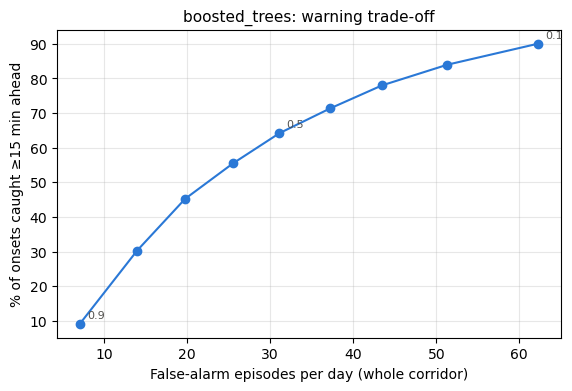

,caught ≥15 min,false alarms / day,wrong-alert hours / day,alerts right,median lead (min)
threshold,,,,,
0.1,0.900,62.232,18.483,0.757,30.0
0.2,0.840,51.336,12.013,0.824,30.0
0.3,0.780,43.456,8.757,0.863,30.0
0.4,0.714,37.221,6.650,0.890,25.0
0.5,0.642,31.107,5.033,0.913,25.0
0.6,0.555,25.496,3.755,0.932,20.0
0.7,0.452,19.747,2.641,0.949,20.0
0.8,0.303,13.963,1.640,0.966,15.0
0.9,0.091,7.077,0.677,0.984,10.0


In [8]:
thresholds = np.round(np.arange(0.1, 0.91, 0.1), 2)
tradeoff = pd.DataFrame([sf.alert_metrics(predictions, predictions["probability"].to_numpy(), t) for t in thresholds],
                        index=pd.Index(thresholds, name="threshold"))

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(tradeoff["false alarms / day"], tradeoff["caught ≥15 min"] * 100, marker="o", color="#2a78d6")
for t in (0.1, 0.5, 0.9):
    ax.annotate(f"{t}", (tradeoff.loc[t, "false alarms / day"], tradeoff.loc[t, "caught ≥15 min"] * 100),
                xytext=(5, 4), textcoords="offset points", fontsize=8, color="#52514e")
ax.set_xlabel("False-alarm episodes per day (whole corridor)")
ax.set_ylabel("% of onsets caught ≥15 min ahead")
ax.set_title(f"{MODEL_NAME}: warning trade-off", fontsize=11)
ax.grid(alpha=0.3)
plt.show()
tradeoff[["caught ≥15 min", "false alarms / day", "wrong-alert hours / day", "alerts right", "median lead (min)"]].round(3)

## 5. Are the probabilities honest? (calibration)
Predictions grouped by predicted probability, compared with how often congestion actually followed. A well-calibrated model sits on the diagonal.

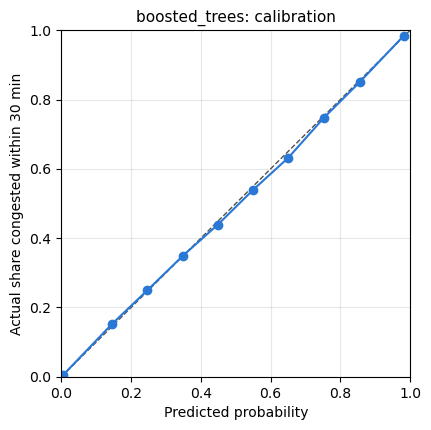

In [9]:
scored = predictions[predictions["y_known"]]
bins = pd.cut(scored["probability"], np.linspace(0, 1, 11), include_lowest=True)
calibration = scored.groupby(bins, observed=True).agg(predicted=("probability", "mean"), actual=("y", "mean"), rows=("y", "size"))
calibration = calibration[calibration["rows"] >= 100]

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="#52514e", linewidth=1)
ax.plot(calibration["predicted"], calibration["actual"], marker="o", color="#2a78d6")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Actual share congested within 30 min")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title(f"{MODEL_NAME}: calibration", fontsize=11)
ax.grid(alpha=0.3)
plt.show()

## 6. Save and compare with the team
Saves this model's per-fold results to `results/<MODEL_NAME>_folds.csv` and its summary row to `results/summary.csv` (replacing any earlier row
with the same name). Quick runs aren't added to the summary. Commit the `results/` folder so everyone sees the same table.

In [10]:
RESULTS = (ROOT / "notebooks" / "results")
RESULTS.mkdir(exist_ok=True)

if QUICK_RUN:
    print("Quick run: results not saved.")
else:
    fold_results.round(4).to_csv(RESULTS / f"{MODEL_NAME}_folds.csv")
    row = {
        "model": MODEL_NAME,
        "date run": date.today().isoformat(),
        "features": len(FEATURES),
        "AP onsets (mean)": fold_results["AP, onsets"].mean(),
        "AP onsets (std)": fold_results["AP, onsets"].std(),
        "AP onsets (worst fold)": fold_results["AP, onsets"].min(),
        "Brier": fold_results["Brier"].mean(),
        "caught ≥15 min @0.5": fold_results["caught ≥15 min"].mean(),
        "false alarms/day @0.5": fold_results["false alarms / day"].mean(),
        "wrong-alert hours/day @0.5": fold_results["wrong-alert hours / day"].mean(),
    }
    summary_file = RESULTS / "summary.csv"
    summary = pd.read_csv(summary_file) if summary_file.exists() else pd.DataFrame()
    if len(summary):
        summary = summary[summary["model"] != MODEL_NAME]
    summary = pd.concat([summary, pd.DataFrame([row])], ignore_index=True).sort_values("AP onsets (mean)", ascending=False)
    summary.round(4).to_csv(summary_file, index=False)
    print(f"Saved {RESULTS / f'{MODEL_NAME}_folds.csv'} and updated {summary_file}")

pd.read_csv(RESULTS / "summary.csv").set_index("model").round(3) if (RESULTS / "summary.csv").exists() else None

Saved results/boosted_trees_folds.csv and updated results/summary.csv


,date run,features,AP onsets (mean),AP onsets (std),AP onsets (worst fold),Brier,caught ≥15 min @0.5,false alarms/day @0.5,wrong-alert hours/day @0.5
model,,,,,,,,,
boosted_trees,2026-11-02,29,0.766,0.011,0.755,0.022,0.641,31.124,5.038
transformer_shared_plus_agreed_features,2026-10-31,29,0.762,0.017,0.732,0.022,0.663,30.432,5.544
random_forest_shared_29_features,2026-10-31,29,0.750,0.009,0.738,0.023,0.526,30.048,4.462


## Adding a feature
Features are shared: add them in the **TEAM FEATURES** section at the bottom of `safeflow_features.py` (instructions and an example are there),
not in this notebook. A new feature joins `sf.SHARED_FEATURES` for everyone. Rerun your notebook to update your results.
Results saved before a feature change aren't directly comparable with results after it.